In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,cstag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,94,94,Boisterous toddler board books join the phenom...,"PreS-Gr 1-This book is a fun, interactive way ...",0.2468,0.0000,0.1299,0.8207,0.8303,0.8255,4,8,7,1,False,1-5
1,119,119,"The Banks children, Jane and Michael, change n...","""An enchanting tale of a young girl's adventur...",0.1154,0.0291,0.0769,0.8052,0.7970,0.8011,1,2,4,10,False,6-10
2,132,132,A festive Scarry classic now available in pict...,Theodor Geisel was born in 1904 in Springfield...,0.1856,0.0138,0.1375,0.7894,0.8022,0.7958,1,6,7,18,False,16-20


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


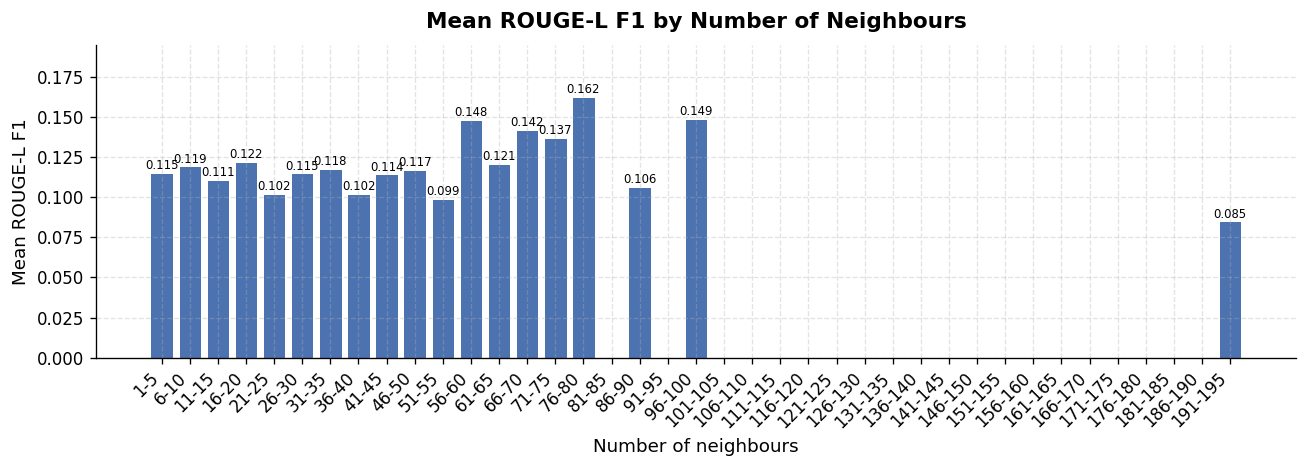

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

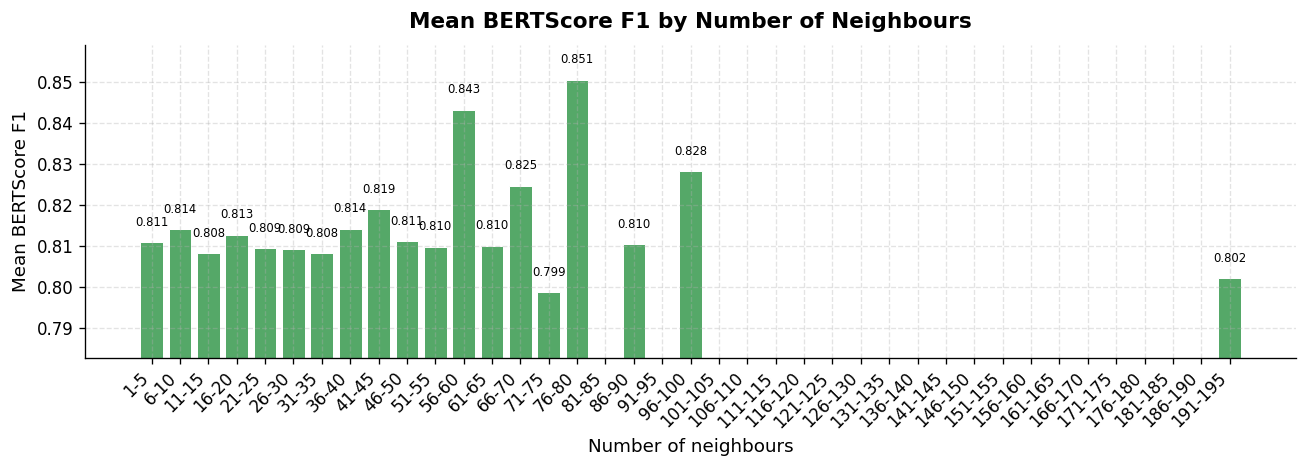

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

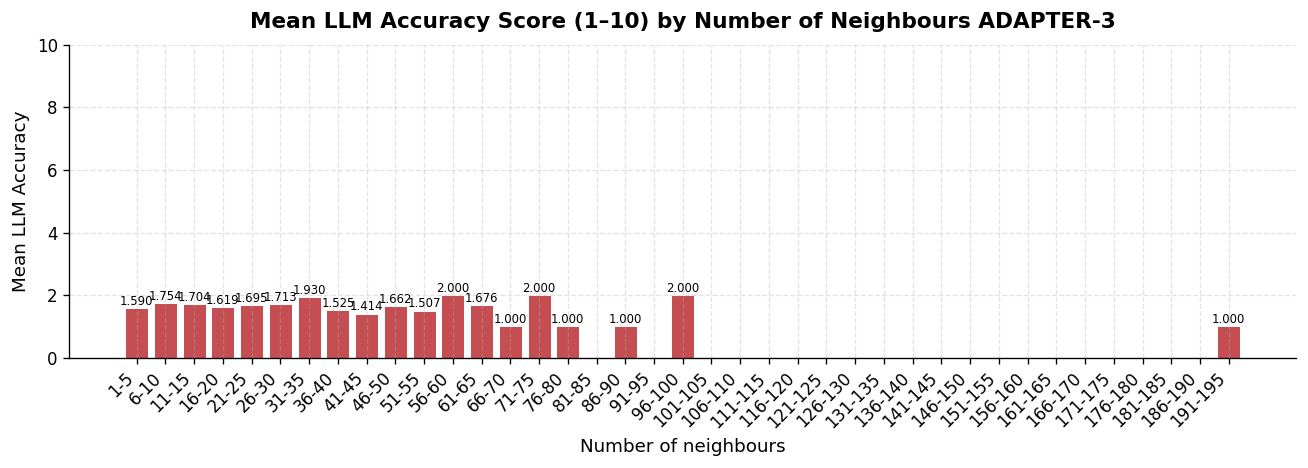

1.656084656084656
1.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

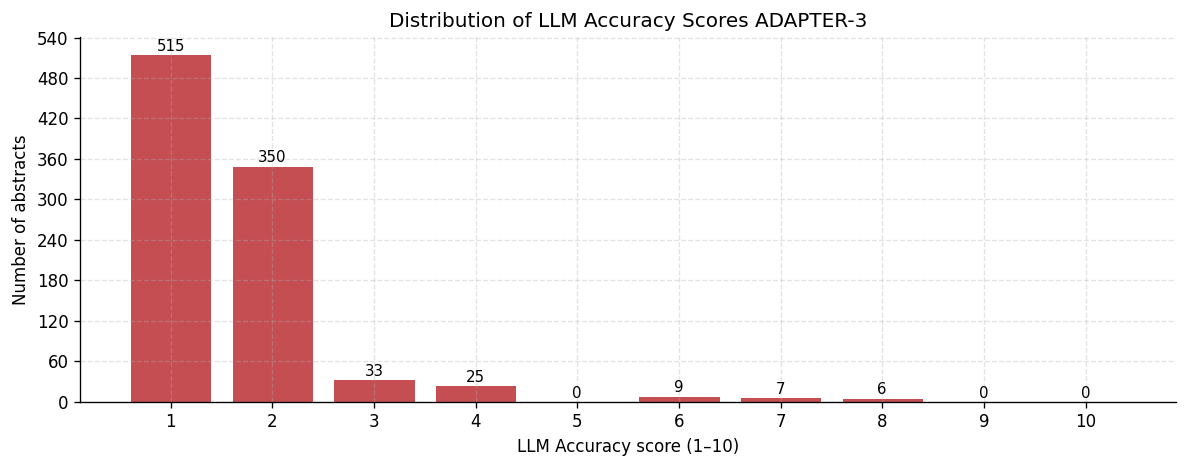

llm_accuracy
1     515
2     350
3      33
4      25
5       0
6       9
7       7
8       6
9       0
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

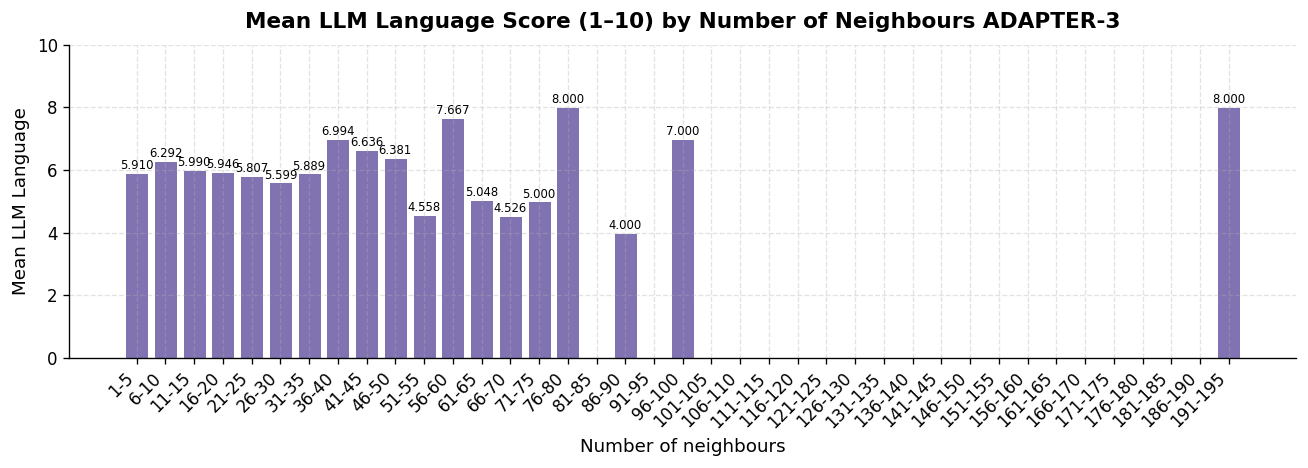

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

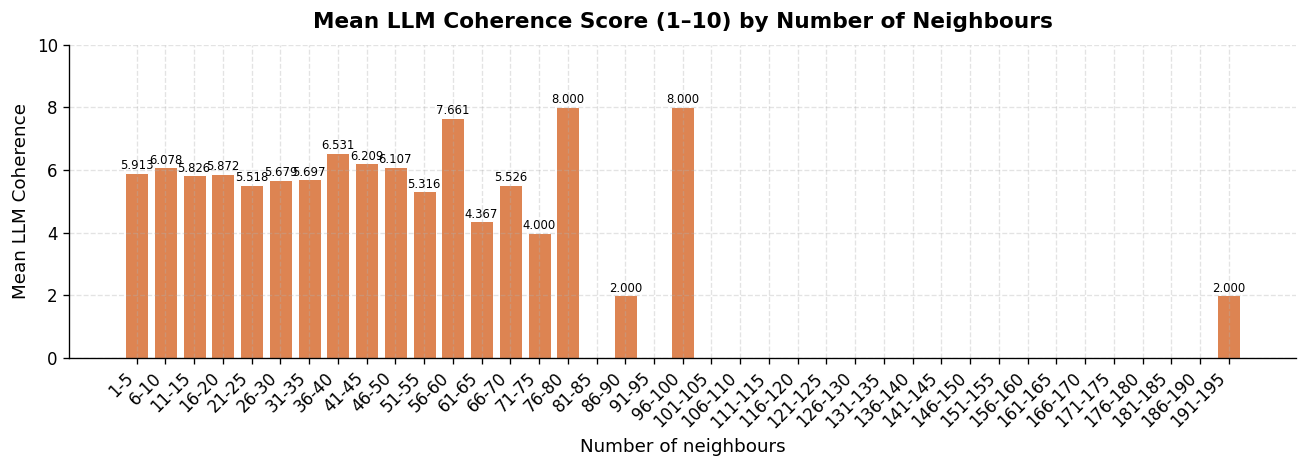

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

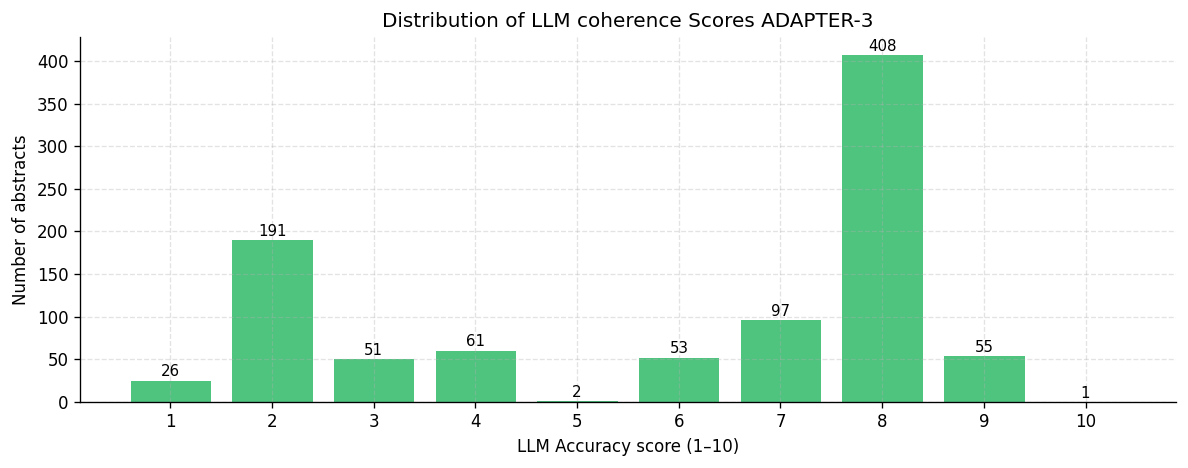

llm_coherence
1      26
2     191
3      51
4      61
5       2
6      53
7      97
8     408
9      55
10      1
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [10]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 217 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      1.6561
Mean llm_accuracy (excluding 1,2): 1.8516


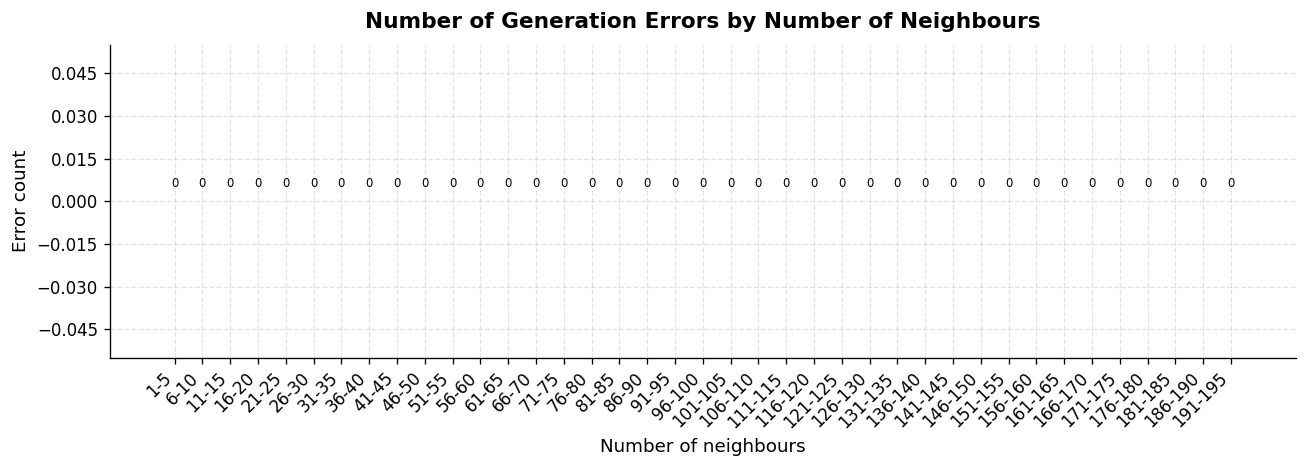

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_15174/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,36284,"Kindergarten-Grade 2Katie has always wanted a pony, and she is about to get her wish. She has earned it by helping in the barn and taking riding lessons. However, the search for the perfect pony takes longer than she expected. One is too spirited, another too stubborn, and still another is too young. Then she and her mother find a shaggy, mud-covered pony that Katie declares is too dirty. After lots of grooming, she rides him and they get along wonderfully. Even if he isn't sleek and fast, she knows that she has found just the right animal for her. Katie is an appealing heroine who is willing to work hard for what she wants and smart enough to realize that first appearances can be deceiving. The warmth of the mother/daughter relationship shines through in the cheerful watercolor-and-pencil illustrations that also feature an engaging variety of ponies whose antics will be familiar to young equestrians and entertaining to all readers. The pastoral landscapes, nicely detailed riding and stable backgrounds, and expressive characters reinforce the mood of the text to create a congenial equestrian adventure.Carol Schene, formerly at Taunton Public Schools, MA Copyright Reed Business Information, a division of Reed Elsevier Inc. All rights reserved.Saddle up, young horse lovers who dream of having a horse of their own. In a first-person narrative, a young girl, whose first word was pony, talks about her riding her brother's horse, a barn stall empty and waiting, and, at last, the challenge of finding a horse for herself--one was too nervous, one was too stubborn, and one was too scary. Naturally, it's the muddy, shaggy pony that turns out to be perfect--the girl's dream come true. McNicholas' realistic watercolor illustrations are completely in step with the understated text and the experience itself. Julie CumminsCopyright American Library Association. All rights reserved","""An absorbing, well-researched story that will appeal to readers of all ages."" -- School Library Journal, starred review""An absorbing, well researched story that will appeal to all ages."" -- School Libary Journal, starred review""Readers will be drawn in by the story's emotional core and the historical details."" -- Publishers Weekly, starred review""Reads like a novel, but is based on real events."" -- Kirkus Reviews, starred review""Read this book. It's a must-read for all ages."" -- The New York Times Book Review""Read this book. Its a must-read for all agess."" -- The New York Time Book Review""Read this. Its a must-read."" -- The New York Timess Book Review""Read this."" -- The New York TImes Book Review""Read this"" -- The New York TimesBook Review""Read this."" The New York Times BookReview""Read this."" --The New York Times Book Review""A compelling story of courage and hope."" -- Booklist, starred review""A compelling story of courageand hope."" -- Booklist""A compelling story of courage. -- Booklist""A compellingstory of courage and hope."" Booklist""A compelling storyof courage and hope."" --Booklist""A compelling story ofcourage and hope."" --Booklis""A compelling story of courage."" -- Booklist""A powerful story of courage and hope that will inspire readers of all ages.""-- Kirkus Reviews""A powerful story of courageand hope that will inspire readersof all ages."" -- Kirkus Reviews""A powerfulstory of courage and hope thatwill inspire readers of allages."" -- Kirkus Reviews""An inspiring story of courage and hope, told with grace and sensitivity."" -- Publishers Weekly""An inspiring story ofcourage andhope, told with grace andsensitivity."" -- Publishers Weekly""Read this book. Ite's a must-read forall ages."" -- The NewYork Times Book Review""Readthis book. It's amust-read for allages."" -- The New YorkTimes Book Review""Read thisbook. It's a mustread for allages."" --The New YorkTimes Book Review""A compelling storyof courageand hope."" --Booklist, starredreview""A compelling 

In [13]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_15174/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,36023,"Kindergarten-Grade 3Simple prose introduces two animals, a cat and a dog, that survived Hurricane Katrina in New Orleans, and, after four months of wandering, were rescued by the Best Friends Animal Society. The narrative is obviously part supposition as the original owners were never found, despite efforts to locate them. Since both pets had bobbed tails, a shelter volunteer named them Bob Cat and Bobbi, hence the book's title. It was soon discovered that Bob Cat was blind, making his survival even more amazing and underscoring the idea that the two critters relied on one another during their ordeal. The terrifying event is told about in a matter-of-fact way, with the text concentrating on the ""feel good"" aspect of the two Bobbies. The gouache illustrations, done in soft pastel shades, present realistic glimpses of the devastated city that serve as a backdrop for the animals' struggles. An afterword includes a photo and additional information. An excellent introduction to Katrina for young children, this touching animal tale memorializes a modern catastrophe and pays tribute to the many volunteers who traveled to New Orleans to help.Judith Constantinides, formerly at East Baton Rouge Parish Main Library, LA Copyright Reed Business Information, a division of Reed Elsevier Inc. All rights reserved.Neither Bobbi the dog nor Bob Cat has a tail, and some say thats what brought them together. Abandoned during the Katrina evacuations, pets Bobbi and Bob Cat wander dangerous, debris-strewn streets seeking food and water. Eventuallytaken to a rescue shelter, the Bobbies show distress when separated but remain calm when together. Workers then discover that Bob Cat is blind and that Bobbi seems to serve as his seeing-eye dog. A national news appearance ultimately results in the animals'shared adoptionin a happy new home. The descriptive, sometimes folksy prose and realistically rendered gouache illustrations accessibly convey the Bobbies experiences and mutual devotion. A...","""An excellent choice for classroom use, this book will also be a favorite with young readers who enjoy stories about animals and the natural world."" --School Library Journal, starred review""An excellent choice for classrooms, this book will also appeal to young readers who enjoy stories of animals and the natural world. A great addition to any library."" --School Library Journal""An excellent choice for use in the classroom, this book will also have a wide appeal to young readers who love stories about animals and the world around them. A great addition to the library."" --School Library Jounral""An excellent choice for the classroom, this book is also a favorite with young readers. A great addition to your library."" --School LibraryJournal""An excellent choice for class use, this book will be a favorite with young people who enjoy stories about animals. A great addition to libraries."" --School Library Journal",1
1,39388,"Its a warmhearted portrait of an endlessly patient parent, ready tohelp her child work through his fears and desires.The illustrations . . . perfectly match the nonthreatening tone of thetext.Eve Bunting, who has written many books for children, including Pirate Boy, was inspired to write Washday when she came across a set of washing instructions written long before the days of electric washers and dryers. She lives in California with her husband.Julie Fortenberry is an abstract painter and a children’s book illustrator. She has a Master’s Degree in Fine Arts from Hunter College. Her illustrations have appeared in Sadie’s Sukkah Breakfast (Kar-Ben) and Pippa at the Parade (Boyds Mills Press). She lives in Westchester County, New York.","""An entertaining read-aloud."" --Kirkus Reviews""An entertaining read-aloudbut not for the faint of heart."" --Kirkus ReviewsWith a pirate's eye and a pirate's grin, a pirate's hook and a pirate's grin...the pirate's hook and a pirates gri

In [14]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


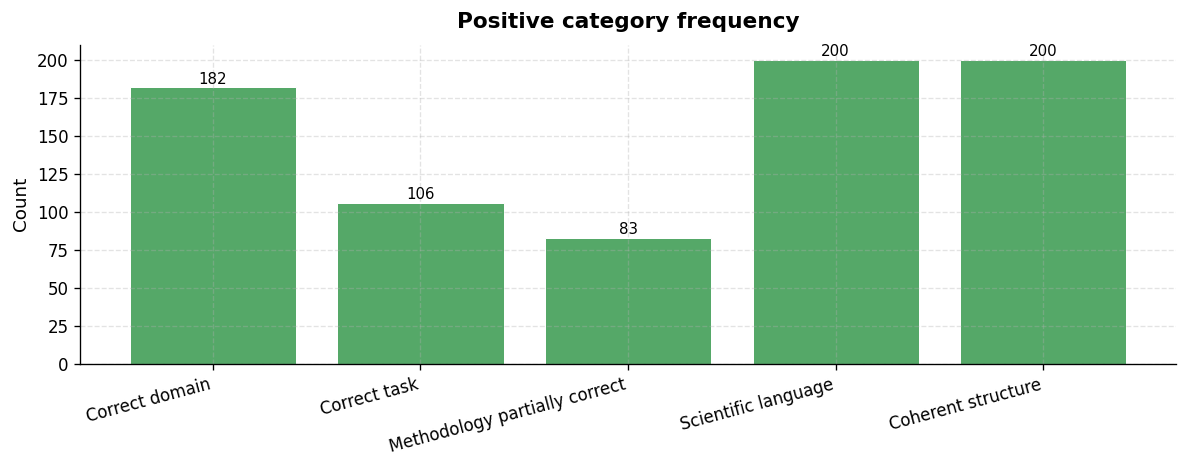

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()